In [31]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd
from pathlib import Path
from shapely.geometry import box
from matplotlib.collections import LineCollection


# ============================================================
# USER PATHS
# ============================================================

NC_FILE = r"C:\Users\Lara\SOCIB_LPF\Data_cruises\dep0122_socib-rv_scb-tsl001_L1_2026-07-13.nc"
BATHY_FILE = r"C:\Users\Lara\SOCIB_LPF\Phyton_codes\figuras_cabrera_expert\GEBCO_27_Mar_2026\gebco_2025_n40.5_s38.0_w0.0_e5.0.nc"
ais_path = r"C:\Users\Lara\SOCIB_LPF\Phyton_codes\figuras_cabrera_expert\pn-cbr_tcm30-63106\PNMT_Archipielago_Cabrera\AIS\AIS_Archipielago_Cabrera.shp"
limite_path = r"C:\Users\Lara\SOCIB_LPF\Phyton_codes\PNMT_Archipielago_Cabrera\Limites\Limite_Archipielago_Cabrera.shp"


<xarray.Dataset> Size: 10MB
Dimensions:            (time: 789, depth_adcp4: 50)
Coordinates:
  * time               (time) datetime64[ns] 6kB 2026-07-13T07:28:10 ... 2026...
    LAT                (time) float64 6kB ...
    LON                (time) float64 6kB ...
    DEPTH_ADCP4        (depth_adcp4) float64 400B ...
Dimensions without coordinates: depth_adcp4
Data variables: (12/78)
    trajectory         |S22 22B ...
    QC_LAT             (time) float32 3kB ...
    QC_LON             (time) float32 3kB ...
    VEL_NOR            (time, depth_adcp4) float64 316kB ...
    QC_VEL_NOR         (time, depth_adcp4) float32 158kB ...
    VEL_EAS            (time, depth_adcp4) float64 316kB ...
    ...                 ...
    QC_BT_DEPTH_BEAM3  (time) float32 3kB ...
    BT_DEPTH_BEAM4     (time) float64 6kB ...
    QC_BT_DEPTH_BEAM4  (time) float32 3kB ...
    BT_DEPTH_MIN       (time) float64 6kB ...
    QC_BT_DEPTH_MIN    (time) float32 3kB ...
    AMP_BEAM_AVG       (time, depth_adcp4) 

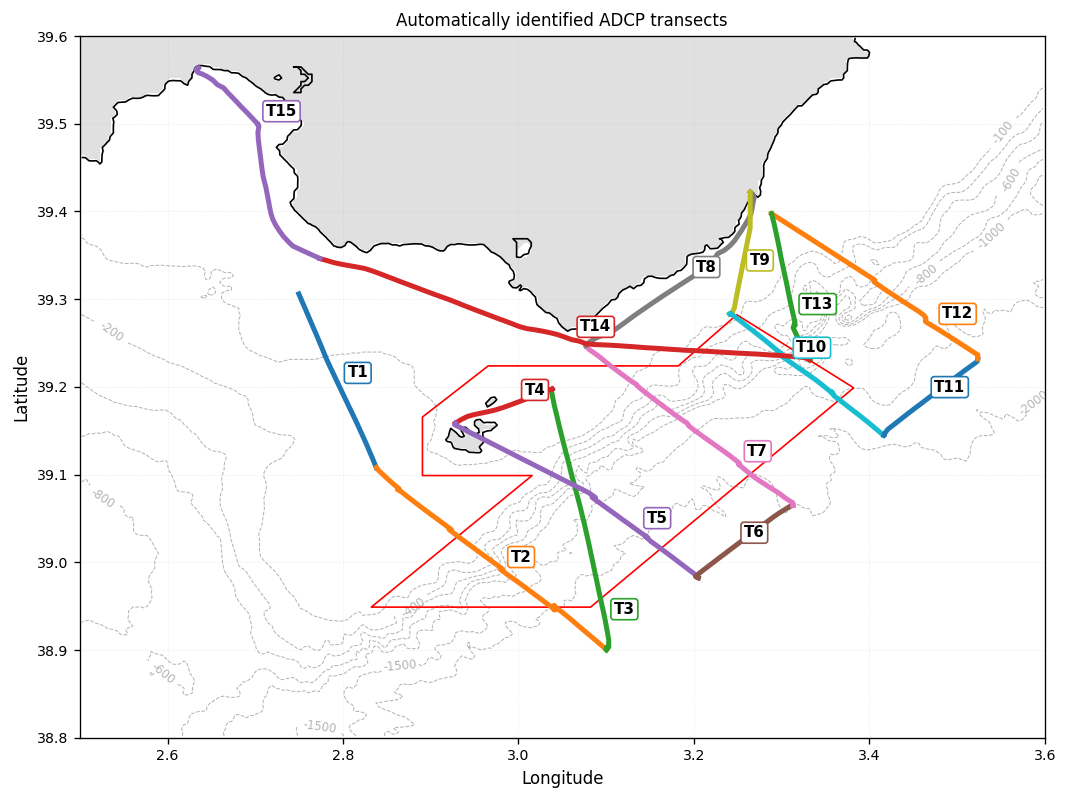


Common velocity scale: -0.2512817838751158 to 0.2512817838751158 m/s


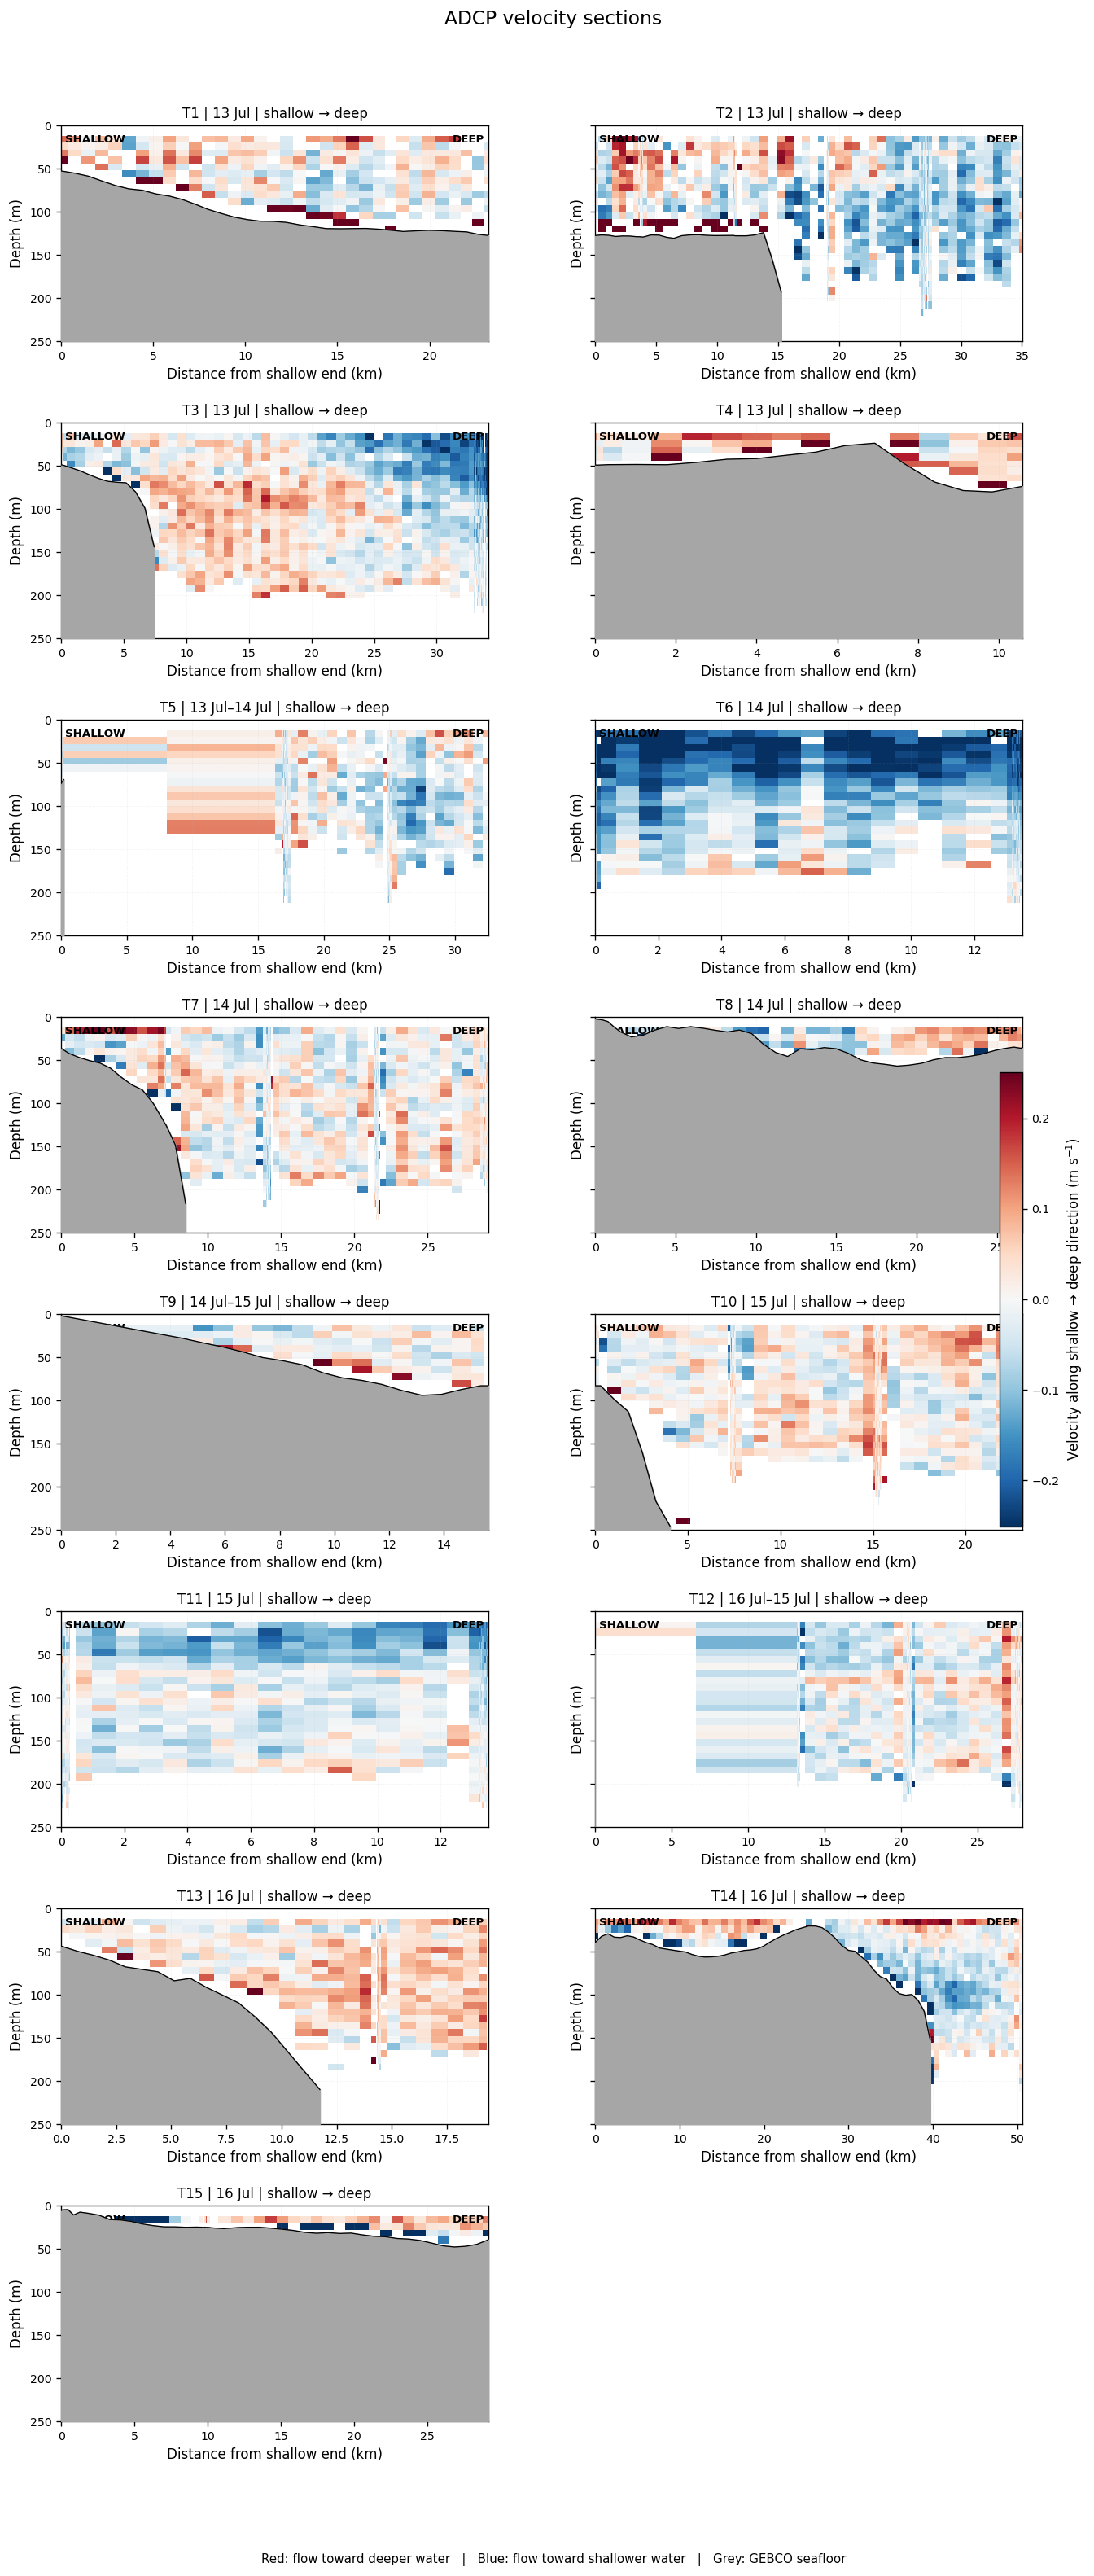

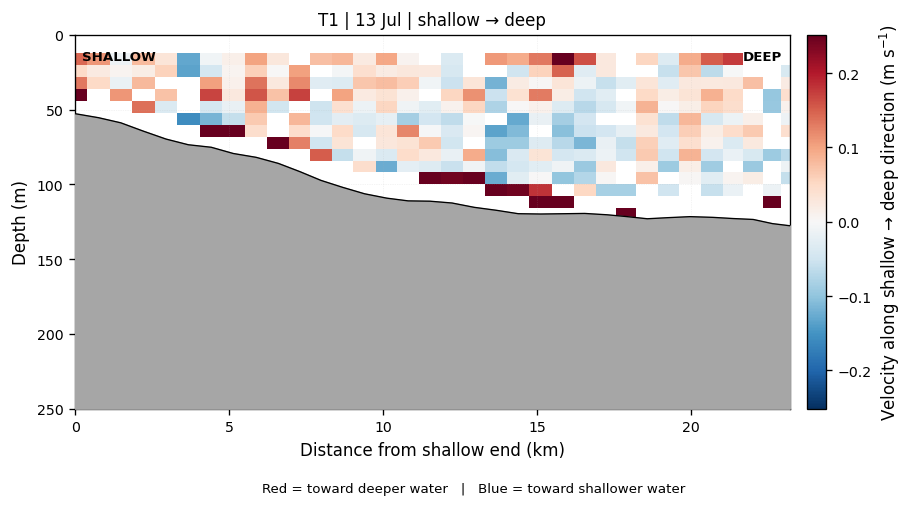

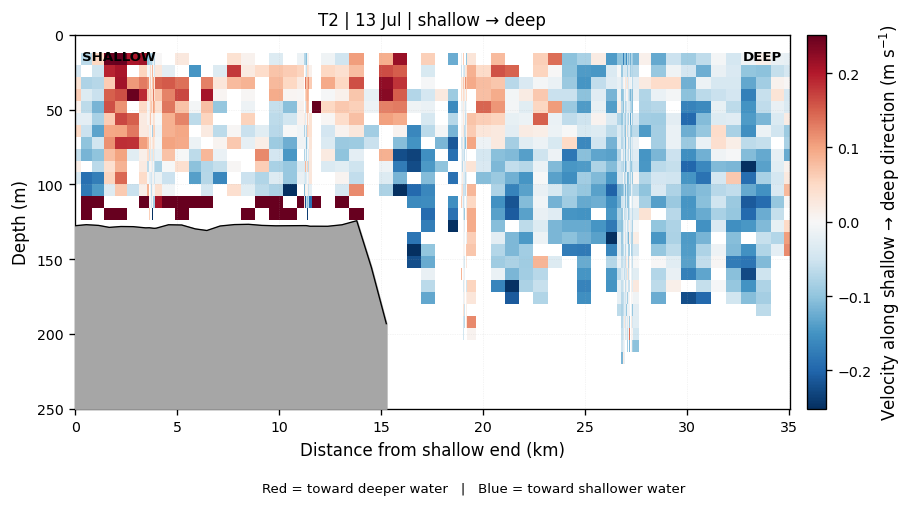

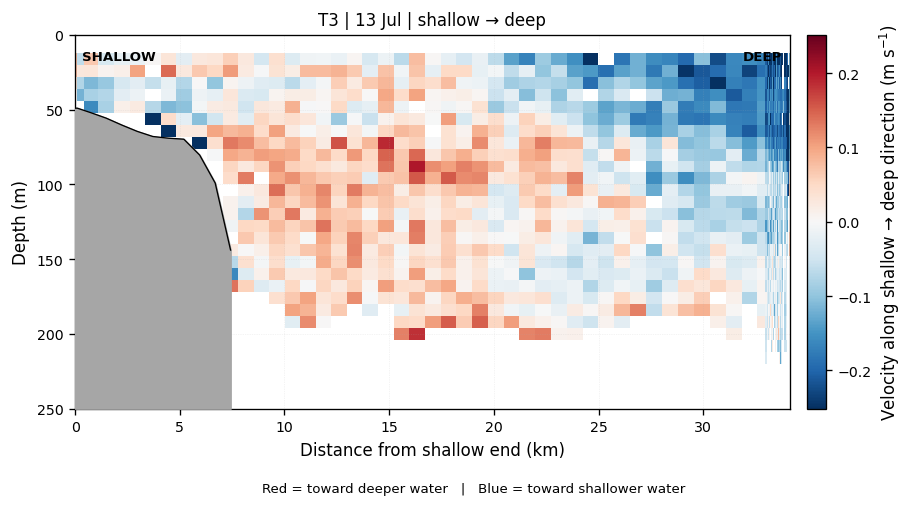

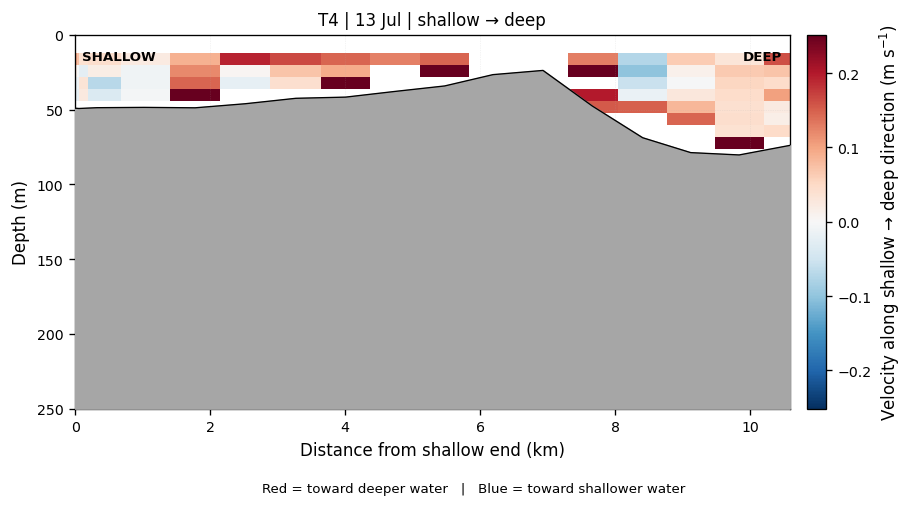

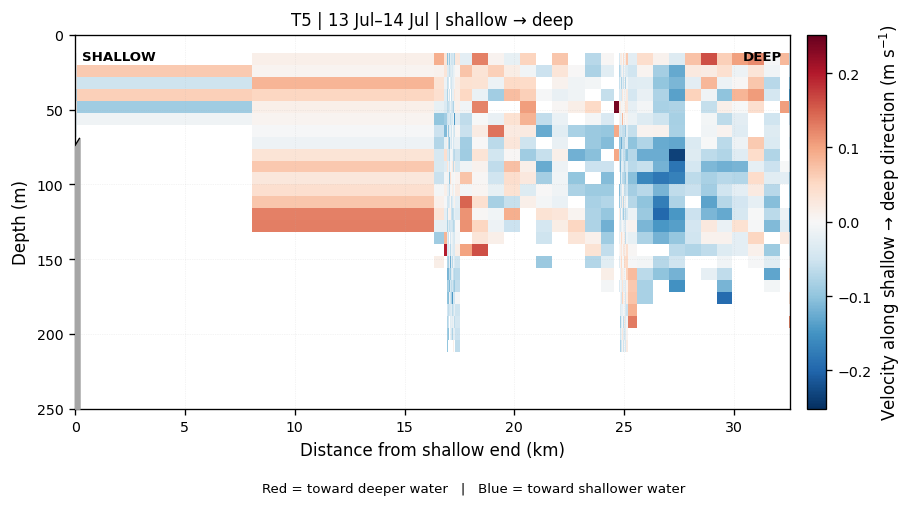

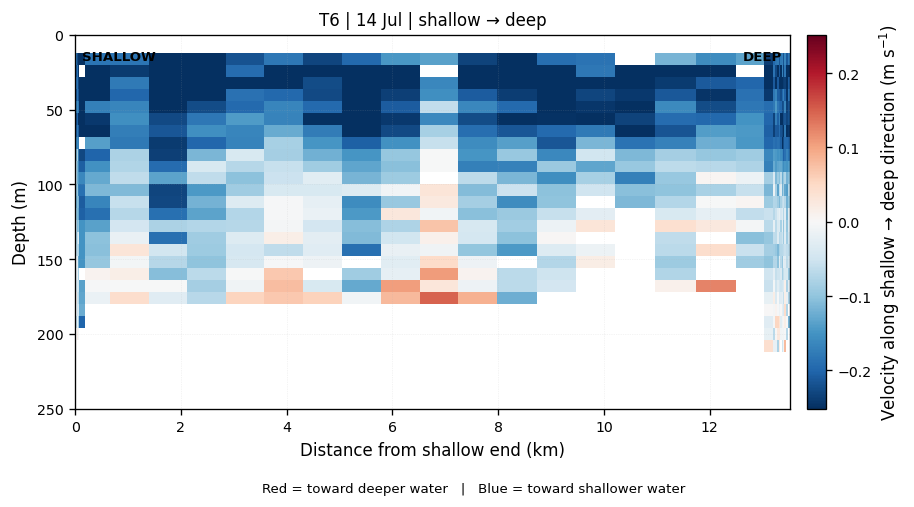

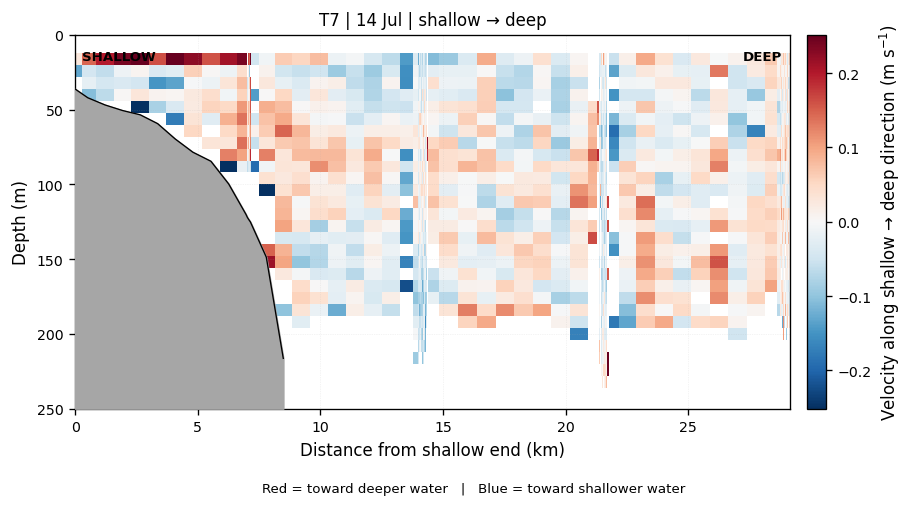

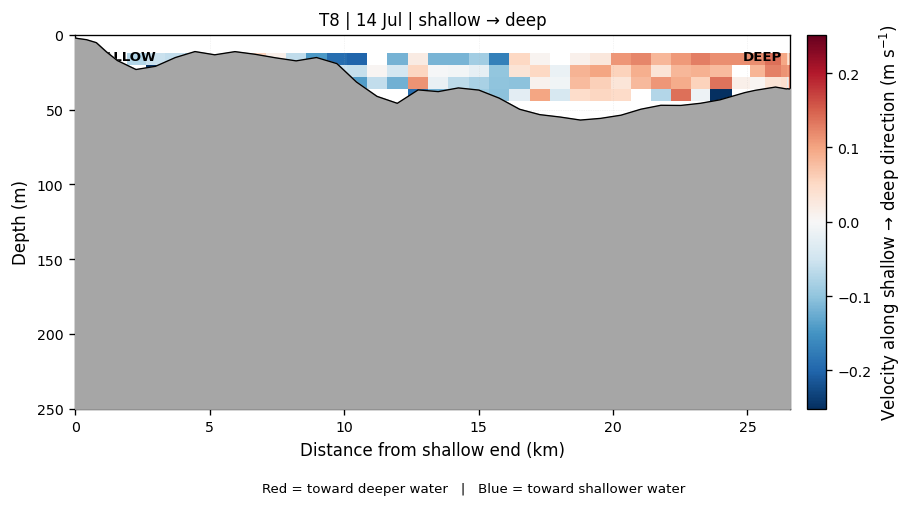

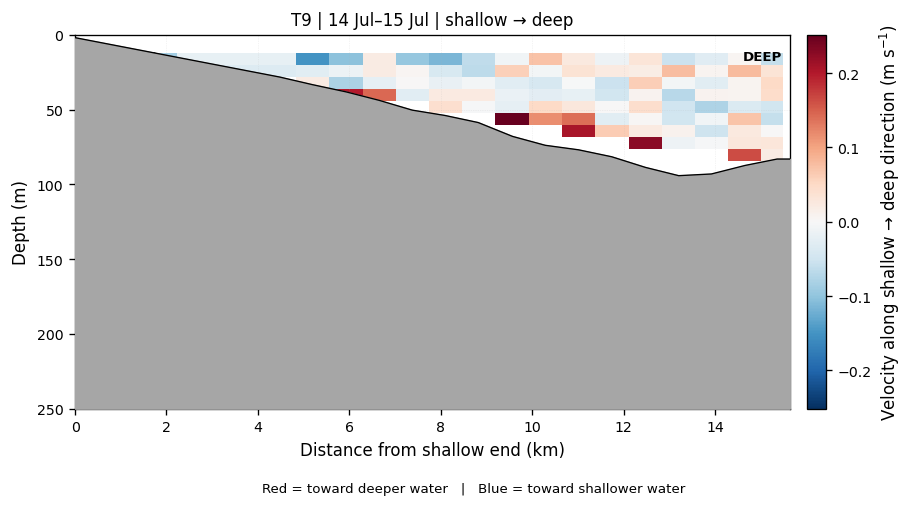

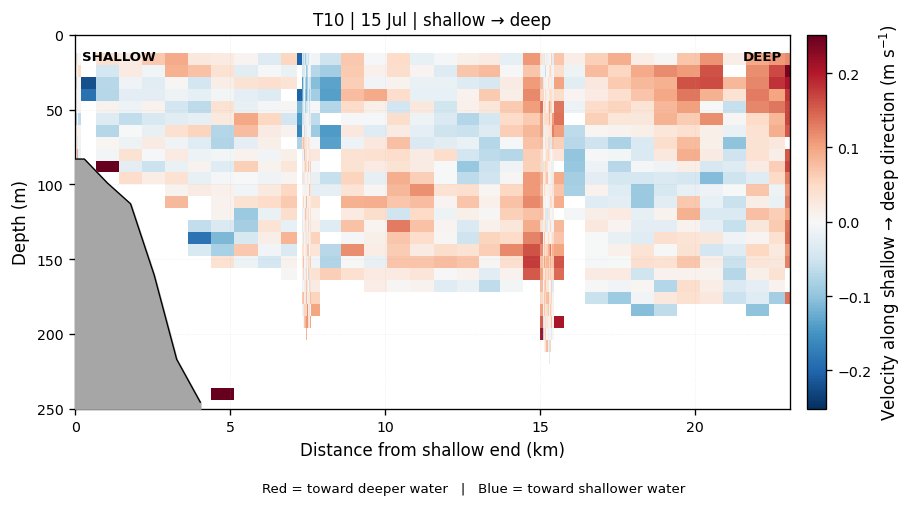

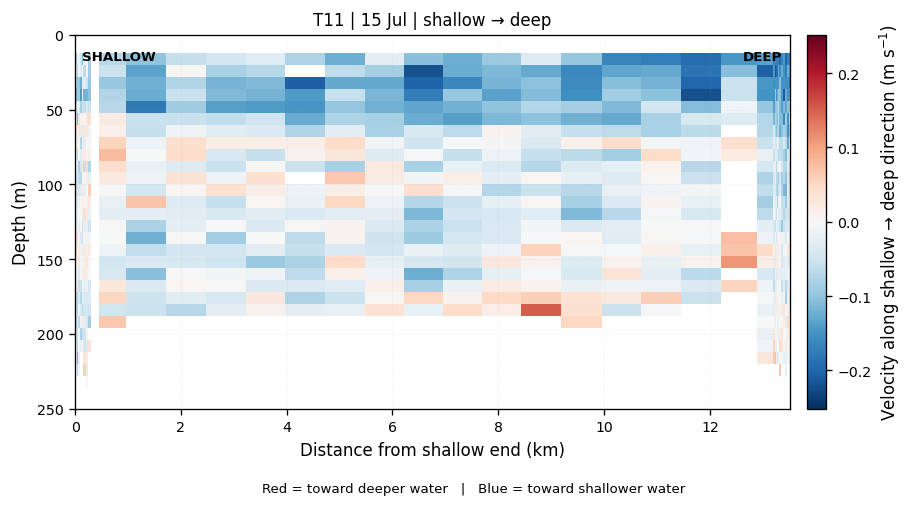

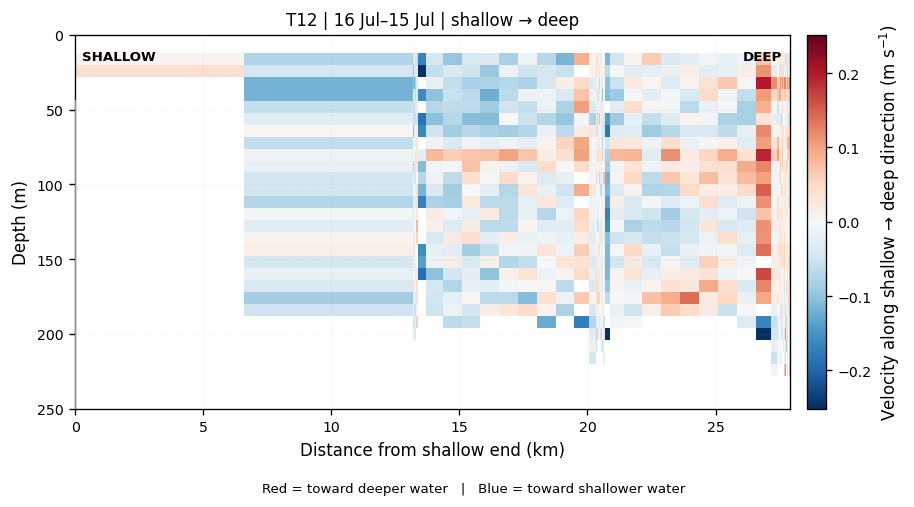

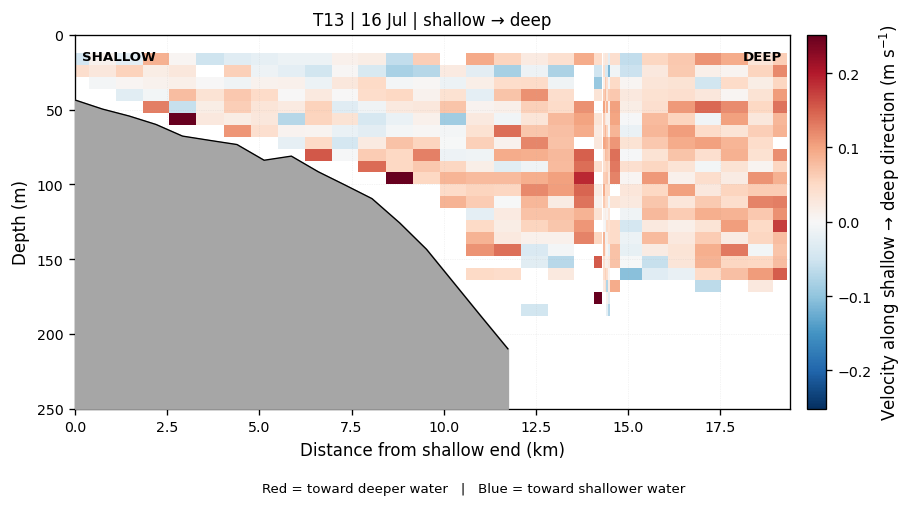

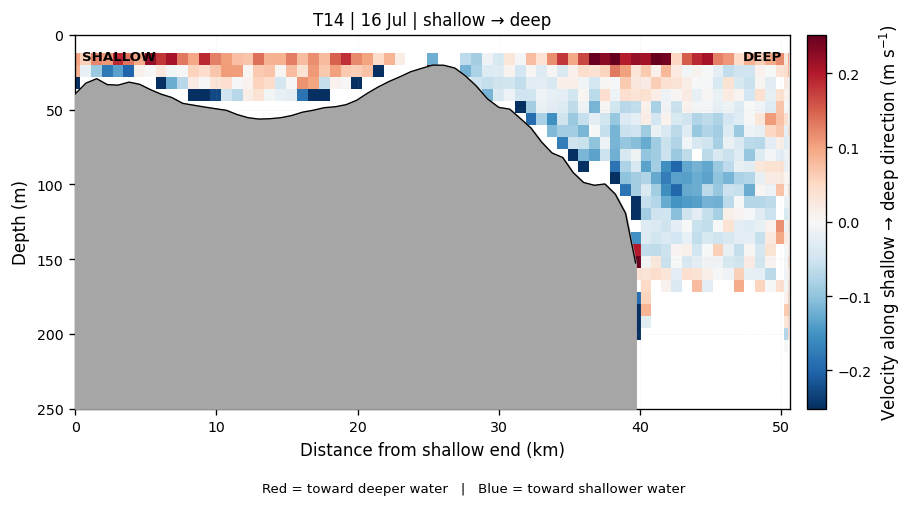

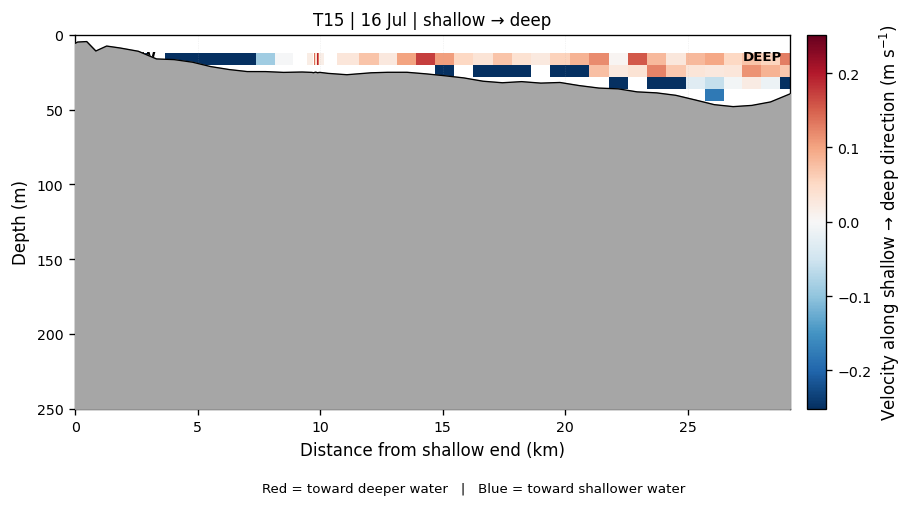

In [19]:
# ============================================================
# OUTPUT
# ============================================================

OUTDIR = Path(ADCP_FILE).parent / "figuras_adcp_sections"
OUTDIR.mkdir(exist_ok=True)

SAVE_FIGS = True


# ============================================================
# MAP DOMAIN
# ============================================================

xmin, xmax = 2.5, 3.6
ymin, ymax = 38.8, 39.6


# ============================================================
# QUALITY CONTROL
# ============================================================

GOOD_QC = [1, 2]


# ============================================================
# AUTOMATIC TRANSECT DETECTION SETTINGS
# ============================================================
#
# SIMPLIFY_TOLERANCE_KM:
#   higher -> fewer / longer transects
#   lower  -> more transects
#
# MIN_TRANSECT_LENGTH_KM:
#   ignores short manoeuvres / small loops
# ============================================================

SIMPLIFY_TOLERANCE_KM = 5.0

MIN_TRANSECT_LENGTH_KM = 8.0

MIN_TRANSECT_POINTS = 8


# ============================================================
# SECTION SETTINGS
# ============================================================

# ADCP data reach about 400 m in this file.
SECTION_MAX_DEPTH = 250

# Robust colour limits
VELOCITY_PERCENTILE = 98

# Number of columns in multipanel figure
N_COLS = 2

# Plot individual sections too?
SAVE_INDIVIDUAL_SECTIONS = True


# ============================================================
# MATPLOTLIB STYLE
# ============================================================

plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.facecolor": "white"
})


# ============================================================
# LOAD ADCP
# ============================================================

ds = xr.open_dataset(ADCP_FILE)

print(ds)


# ============================================================
# ADCP VARIABLES
# ============================================================

time = pd.to_datetime(ds["time"].values)

lon = ds["LON"].values.astype(float)
lat = ds["LAT"].values.astype(float)

depth = ds["DEPTH_ADCP4"].values.astype(float)

u = ds["VEL_EAS"].values.astype(float).copy()
v = ds["VEL_NOR"].values.astype(float).copy()

qc_u = ds["QC_VEL_EAS"].values
qc_v = ds["QC_VEL_NOR"].values

qc_lon = ds["QC_LON"].values
qc_lat = ds["QC_LAT"].values


# ============================================================
# QUALITY CONTROL
# ============================================================

valid_uv = (
    np.isin(qc_u, GOOD_QC)
    &
    np.isin(qc_v, GOOD_QC)
)

u[~valid_uv] = np.nan
v[~valid_uv] = np.nan


valid_position = (
    np.isin(qc_lon, GOOD_QC)
    &
    np.isin(qc_lat, GOOD_QC)
    &
    np.isfinite(lon)
    &
    np.isfinite(lat)
)

lon[~valid_position] = np.nan
lat[~valid_position] = np.nan


# ============================================================
# LOAD GEBCO
# ============================================================

bathy = xr.open_dataset(BATHY_FILE)


lon_name = [
    c for c in bathy.coords
    if c.lower() in ["lon", "longitude", "x"]
][0]

lat_name = [
    c for c in bathy.coords
    if c.lower() in ["lat", "latitude", "y"]
][0]


if "elevation" in bathy:

    z_name = "elevation"

elif "z" in bathy:

    z_name = "z"

else:

    raise ValueError(
        "No bathymetry variable found in GEBCO file."
    )


# ============================================================
# FUNCTION: GEBCO DEPTH AT SHIP POSITION
# ============================================================

def get_bottom_depth(lons, lats):

    lon_da = xr.DataArray(
        np.asarray(lons),
        dims="points"
    )

    lat_da = xr.DataArray(
        np.asarray(lats),
        dims="points"
    )


    z = bathy[z_name].interp(
        {
            lon_name: lon_da,
            lat_name: lat_da
        }
    ).values


    # GEBCO elevation is negative underwater
    bottom = -z

    bottom[bottom < 0] = 0

    return bottom


# ============================================================
# BOTTOM ALONG FULL SHIP TRACK
# ============================================================

bottom_full = np.full(
    len(lon),
    np.nan
)


valid_geo = (
    np.isfinite(lon)
    &
    np.isfinite(lat)
)


bottom_full[valid_geo] = get_bottom_depth(
    lon[valid_geo],
    lat[valid_geo]
)


# ============================================================
# DISTANCE FUNCTION
# ============================================================

def cumulative_distance_km(lons, lats):

    lons = np.asarray(lons)
    lats = np.asarray(lats)


    if len(lons) == 0:

        return np.array([])


    lat_mean = np.nanmean(lats)


    dx = (
        np.diff(lons)
        *
        111.32
        *
        np.cos(
            np.deg2rad(lat_mean)
        )
    )

    dy = (
        np.diff(lats)
        *
        110.57
    )


    segment_distance = np.sqrt(
        dx**2 + dy**2
    )


    return np.concatenate([
        [0],
        np.cumsum(segment_distance)
    ])


# ============================================================
# DISTANCE BETWEEN TWO POSITIONS
# ============================================================

def point_distance_km(
    lon1,
    lat1,
    lon2,
    lat2
):

    lat_mean = (
        lat1 + lat2
    ) / 2


    dx = (
        (lon2 - lon1)
        *
        111.32
        *
        np.cos(
            np.deg2rad(lat_mean)
        )
    )

    dy = (
        (lat2 - lat1)
        *
        110.57
    )


    return np.sqrt(
        dx**2 + dy**2
    )


# ============================================================
# CONVERT SHIP TRACK TO LOCAL KM COORDINATES
# ============================================================

good_track_idx = np.where(
    valid_geo
)[0]

lon_good = lon[
    good_track_idx
]

lat_good = lat[
    good_track_idx
]


lat0 = np.nanmean(
    lat_good
)


x_good = (
    lon_good - lon_good[0]
) * 111.32 * np.cos(
    np.deg2rad(lat0)
)

y_good = (
    lat_good - lat_good[0]
) * 110.57


# ============================================================
# SIMPLIFY TRACK
# ============================================================
#
# This identifies the main turning points.
# ============================================================

line = LineString(
    np.column_stack([
        x_good,
        y_good
    ])
)


simplified = line.simplify(
    SIMPLIFY_TOLERANCE_KM,
    preserve_topology=False
)


vertices = np.asarray(
    simplified.coords
)


print(
    "\nSimplified track vertices:",
    len(vertices)
)


# ============================================================
# MATCH SIMPLIFIED VERTICES TO ORIGINAL ADCP OBSERVATIONS
# ============================================================

vertex_indices = []


for vx, vy in vertices:

    distance_to_vertex = np.sqrt(
        (x_good - vx)**2
        +
        (y_good - vy)**2
    )


    nearest_local_idx = np.argmin(
        distance_to_vertex
    )


    original_idx = good_track_idx[
        nearest_local_idx
    ]


    vertex_indices.append(
        original_idx
    )


vertex_indices = np.array(
    vertex_indices
)


# Make sure they follow chronological order
vertex_indices = np.unique(
    vertex_indices
)

vertex_indices.sort()


# ============================================================
# CREATE CANDIDATE TRANSECTS
# ============================================================

transects = []


for i in range(
    len(vertex_indices) - 1
):

    i0 = vertex_indices[i]
    i1 = vertex_indices[i + 1]


    if i1 <= i0:
        continue


    npoints = (
        i1 - i0 + 1
    )


    if npoints < MIN_TRANSECT_POINTS:
        continue


    lon_seg = lon[i0:i1 + 1]
    lat_seg = lat[i0:i1 + 1]


    distance = cumulative_distance_km(
        lon_seg,
        lat_seg
    )


    total_distance = distance[-1]


    if total_distance < MIN_TRANSECT_LENGTH_KM:
        continue


    transects.append({
        "start": i0,
        "end": i1,
        "length": total_distance
    })


print(
    "\nNumber of candidate transects:",
    len(transects)
)


for i, tr in enumerate(
    transects,
    start=1
):

    print(
        f"T{i}: "
        f"{tr['length']:.1f} km | "
        f"{time[tr['start']]} -> "
        f"{time[tr['end']]}"
    )


# ============================================================
# LOAD CABRERA LIMIT
# ============================================================

gdf_lim = gpd.read_file(
    limite_path
)


if (
    gdf_lim.crs is not None
    and
    gdf_lim.crs.to_epsg() != 4326
):

    gdf_lim = gdf_lim.to_crs(
        epsg=4326
    )


bbox = gpd.GeoDataFrame(
    geometry=[
        box(
            xmin,
            ymin,
            xmax,
            ymax
        )
    ],
    crs="EPSG:4326"
)


try:

    gdf_lim = gpd.clip(
        gdf_lim,
        bbox
    )

except Exception:

    pass


# ============================================================
# BATHYMETRY SUBSET FOR MAP
# ============================================================

lat_values = bathy[
    lat_name
].values


if lat_values[0] < lat_values[-1]:

    bathy_sub = bathy.sel({
        lon_name: slice(
            xmin,
            xmax
        ),
        lat_name: slice(
            ymin,
            ymax
        )
    })

else:

    bathy_sub = bathy.sel({
        lon_name: slice(
            xmin,
            xmax
        ),
        lat_name: slice(
            ymax,
            ymin
        )
    })


blon = bathy_sub[
    lon_name
].values

blat = bathy_sub[
    lat_name
].values

bz = bathy_sub[
    z_name
].values


# ============================================================
# OVERVIEW MAP WITH TRANSECTS
# ============================================================

def plot_transect_map():

    fig, ax = plt.subplots(
        figsize=(9, 7)
    )


    # --------------------------------------------------------
    # LAND
    # --------------------------------------------------------

    land = np.ma.masked_where(
        bz < 0,
        bz
    )


    ax.contourf(
        blon,
        blat,
        land,
        levels=[0, 10000],
        colors=["0.88"],
        zorder=0
    )


    # --------------------------------------------------------
    # BATHYMETRY
    # --------------------------------------------------------

    levels = [
        -2000,
        -1500,
        -1000,
        -800,
        -600,
        -400,
        -200,
        -100
    ]


    cs = ax.contour(
        blon,
        blat,
        bz,
        levels=levels,
        colors="0.70",
        linewidths=0.6,
        linestyles="dashed",
        zorder=1
    )


    ax.clabel(
        cs,
        fmt="%d",
        fontsize=7
    )


    # --------------------------------------------------------
    # COASTLINE
    # --------------------------------------------------------

    ax.contour(
        blon,
        blat,
        bz,
        levels=[0],
        colors="black",
        linewidths=1.0,
        zorder=2
    )


    # --------------------------------------------------------
    # PARK LIMIT
    # --------------------------------------------------------

    if not gdf_lim.empty:

        gdf_lim.boundary.plot(
            ax=ax,
            color="red",
            linewidth=1.0,
            zorder=3
        )


    # --------------------------------------------------------
    # FULL TRACK
    # --------------------------------------------------------

    ax.plot(
        lon,
        lat,
        color="0.75",
        linewidth=1.0,
        zorder=4,
        label="Ship track"
    )


    # --------------------------------------------------------
    # TRANSECTS
    # --------------------------------------------------------

    cmap = plt.colormaps[
        "tab10"
    ]


    for n, tr in enumerate(
        transects,
        start=1
    ):

        i0 = tr["start"]
        i1 = tr["end"]


        segment_lon = lon[
            i0:i1 + 1
        ]

        segment_lat = lat[
            i0:i1 + 1
        ]


        colour = cmap(
            (n - 1) % 10
        )


        ax.plot(
            segment_lon,
            segment_lat,
            linewidth=3,
            color=colour,
            zorder=6
        )


        mid = (
            len(segment_lon)
            // 2
        )


        ax.annotate(
            f"T{n}",
            xy=(
                segment_lon[mid],
                segment_lat[mid]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor=colour,
                linewidth=1
            ),
            zorder=7
        )


    ax.set_xlim(
        xmin,
        xmax
    )

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_xlabel(
        "Longitude"
    )

    ax.set_ylabel(
        "Latitude"
    )


    ax.set_aspect(
        "equal",
        adjustable="box"
    )


    ax.set_title(
        "Automatically identified ADCP transects"
    )


    ax.grid(
        True,
        linestyle="--",
        linewidth=0.4,
        alpha=0.2
    )


    plt.tight_layout()


    if SAVE_FIGS:

        plt.savefig(
            OUTDIR / "ADCP_transects_overview.png",
            dpi=300,
            bbox_inches="tight"
        )


    plt.show()


plot_transect_map()


# ============================================================
# PREPARE A TRANSECT
# ============================================================

def prepare_transect(tr):

    i0 = tr["start"]
    i1 = tr["end"]


    idx = np.arange(
        i0,
        i1 + 1
    )


    lon_t = lon[idx].copy()
    lat_t = lat[idx].copy()

    time_t = time[idx].copy()

    u_t = u[idx, :].copy()
    v_t = v[idx, :].copy()

    bottom_t = bottom_full[
        idx
    ].copy()


    # --------------------------------------------------------
    # DETERMINE SHALLOW / DEEP END
    # --------------------------------------------------------

    # Use a small average around each endpoint
    n_edge = min(
        5,
        len(bottom_t)
    )


    start_bottom = np.nanmedian(
        bottom_t[:n_edge]
    )

    end_bottom = np.nanmedian(
        bottom_t[-n_edge:]
    )


    # --------------------------------------------------------
    # REVERSE IF THE TRANSECT STARTS DEEP
    # --------------------------------------------------------

    if (
        np.isfinite(start_bottom)
        and
        np.isfinite(end_bottom)
        and
        start_bottom > end_bottom
    ):

        lon_t = lon_t[::-1]
        lat_t = lat_t[::-1]
        time_t = time_t[::-1]

        u_t = u_t[::-1, :]
        v_t = v_t[::-1, :]

        bottom_t = bottom_t[::-1]


    # --------------------------------------------------------
    # DISTANCE FROM SHALLOW END
    # --------------------------------------------------------

    distance = cumulative_distance_km(
        lon_t,
        lat_t
    )


    # --------------------------------------------------------
    # TRANSECT UNIT VECTOR
    #
    # shallow -> deep
    # --------------------------------------------------------

    lat_mean = np.nanmean(
        lat_t
    )


    dx = (
        lon_t[-1] - lon_t[0]
    ) * np.cos(
        np.deg2rad(lat_mean)
    )


    dy = (
        lat_t[-1] - lat_t[0]
    )


    norm_direction = np.sqrt(
        dx**2 + dy**2
    )


    if norm_direction == 0:

        raise ValueError(
            "Transect has zero direction."
        )


    east_unit = (
        dx / norm_direction
    )

    north_unit = (
        dy / norm_direction
    )


    # --------------------------------------------------------
    # ROTATE VELOCITY
    #
    # Positive = toward deep end
    # Negative = toward shallow end
    # --------------------------------------------------------

    vel_sd = (
        u_t * east_unit
        +
        v_t * north_unit
    )


    return {
        "lon": lon_t,
        "lat": lat_t,
        "time": time_t,
        "distance": distance,
        "bottom": bottom_t,
        "velocity": vel_sd,
        "start_bottom": bottom_t[0],
        "end_bottom": bottom_t[-1]
    }


# ============================================================
# PREPARE ALL TRANSECTS
# ============================================================

prepared = [
    prepare_transect(tr)
    for tr in transects
]


# ============================================================
# COMMON COLOUR SCALE
# ============================================================

all_velocity = np.concatenate([
    t["velocity"].ravel()
    for t in prepared
])


all_velocity = all_velocity[
    np.isfinite(all_velocity)
]


VEL_MAX = np.nanpercentile(
    np.abs(all_velocity),
    VELOCITY_PERCENTILE
)


print(
    "\nCommon velocity scale:",
    -VEL_MAX,
    "to",
    VEL_MAX,
    "m/s"
)


velocity_norm = mpl.colors.TwoSlopeNorm(
    vmin=-VEL_MAX,
    vcenter=0,
    vmax=VEL_MAX
)


velocity_cmap = plt.colormaps[
    "RdBu_r"
]


# ============================================================
# DRAW ONE SECTION
# ============================================================

def draw_section(
    ax,
    transect,
    number
):

    distance = transect[
        "distance"
    ]

    velocity = transect[
        "velocity"
    ]

    bottom = transect[
        "bottom"
    ]

    transect_time = transect[
        "time"
    ]


    # --------------------------------------------------------
    # VELOCITY FIELD
    # --------------------------------------------------------

    pcm = ax.pcolormesh(
        distance,
        depth,
        velocity.T,
        shading="auto",
        cmap=velocity_cmap,
        norm=velocity_norm,
        zorder=1
    )


    # --------------------------------------------------------
    # BATHYMETRY
    # --------------------------------------------------------
    #
    # Only visible where bottom is shallower than section limit.
    # --------------------------------------------------------

    bottom_plot = np.asarray(
        bottom
    ).copy()


    ax.fill_between(
        distance,
        bottom_plot,
        SECTION_MAX_DEPTH,
        where=(
            bottom_plot
            <=
            SECTION_MAX_DEPTH
        ),
        color="0.65",
        zorder=5
    )


    # Seafloor line
    visible_bottom = np.where(
        bottom_plot
        <=
        SECTION_MAX_DEPTH,
        bottom_plot,
        np.nan
    )


    ax.plot(
        distance,
        visible_bottom,
        color="black",
        linewidth=0.8,
        zorder=6
    )


    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    ax.set_ylim(
        SECTION_MAX_DEPTH,
        0
    )


    ax.set_xlim(
        distance.min(),
        distance.max()
    )


    ax.set_xlabel(
        "Distance from shallow end (km)"
    )


    ax.set_ylabel(
        "Depth (m)"
    )


    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    day0 = pd.Timestamp(
        transect_time[0]
    ).strftime(
        "%d %b"
    )

    day1 = pd.Timestamp(
        transect_time[-1]
    ).strftime(
        "%d %b"
    )


    if day0 == day1:

        date_string = day0

    else:

        date_string = (
            f"{day0}–{day1}"
        )


    ax.set_title(
        f"T{number} | {date_string} | shallow → deep"
    )


    # --------------------------------------------------------
    # TEXT LABELS
    # --------------------------------------------------------

    ax.text(
        0.01,
        0.96,
        "SHALLOW",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8,
        fontweight="bold"
    )


    ax.text(
        0.99,
        0.96,
        "DEEP",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        fontweight="bold"
    )


    ax.grid(
        True,
        linestyle=":",
        linewidth=0.4,
        alpha=0.3
    )


    return pcm


# ============================================================
# MULTIPANEL FIGURE
# ============================================================

n_transects = len(
    prepared
)


n_rows = int(
    np.ceil(
        n_transects / N_COLS
    )
)


fig, axes = plt.subplots(
    n_rows,
    N_COLS,
    figsize=(
        12,
        3.3 * n_rows
    ),
    squeeze=False,
    sharey=True
)


axes_flat = axes.ravel()


last_pcm = None


for i, transect in enumerate(
    prepared
):

    last_pcm = draw_section(
        axes_flat[i],
        transect,
        i + 1
    )


# Hide unused axes
for j in range(
    n_transects,
    len(axes_flat)
):

    axes_flat[j].axis(
        "off"
    )


# ============================================================
# COMMON COLORBAR
# ============================================================

cbar = fig.colorbar(
    last_pcm,
    ax=axes_flat[:n_transects].tolist(),
    orientation="vertical",
    fraction=0.025,
    pad=0.02
)


cbar.set_label(
    "Velocity along shallow → deep direction (m s$^{-1}$)"
)


# ============================================================
# EXPLANATION
# ============================================================

fig.suptitle(
    "ADCP velocity sections",
    fontsize=14,
    y=0.995
)


fig.text(
    0.5,
    0.005,
    "Red: flow toward deeper water   |   Blue: flow toward shallower water   |   Grey: GEBCO seafloor",
    ha="center",
    fontsize=9
)


plt.subplots_adjust(
    top=0.95,
    bottom=0.06,
    left=0.08,
    right=0.90,
    hspace=0.38,
    wspace=0.25
)


if SAVE_FIGS:

    plt.savefig(
        OUTDIR / "ADCP_sections_shallow_to_deep.png",
        dpi=300,
        bbox_inches="tight"
    )


plt.show()


# ============================================================
# OPTIONAL: INDIVIDUAL SECTIONS
# ============================================================

if SAVE_INDIVIDUAL_SECTIONS:

    for i, transect in enumerate(
        prepared,
        start=1
    ):

        fig, ax = plt.subplots(
            figsize=(8, 4.2)
        )


        pcm = draw_section(
            ax,
            transect,
            i
        )


        cbar = fig.colorbar(
            pcm,
            ax=ax,
            pad=0.02
        )


        cbar.set_label(
            "Velocity along shallow → deep direction (m s$^{-1}$)"
        )


        fig.text(
            0.5,
            0.01,
            "Red = toward deeper water   |   Blue = toward shallower water",
            ha="center",
            fontsize=8
        )


        plt.tight_layout(
            rect=[
                0,
                0.04,
                1,
                1
            ]
        )


        if SAVE_FIGS:

            plt.savefig(
                OUTDIR / f"ADCP_section_T{i:02d}.png",
                dpi=300,
                bbox_inches="tight"
            )


        plt.show()

Output directory:
C:\Users\Lara\SOCIB_LPF\Data_cruises\figuras_adcp_combined
C:\Users\Lara\SOCIB_LPF\Data_cruises\figuras_adcp_combined
Near-surface ADCP bin: 16.0 m
150 m target -> actual bin: 152.0 m
Saving figure to:
C:\Users\Lara\SOCIB_LPF\Data_cruises\figuras_adcp_combined\ADCP_uv_3D_and_vector_maps.png


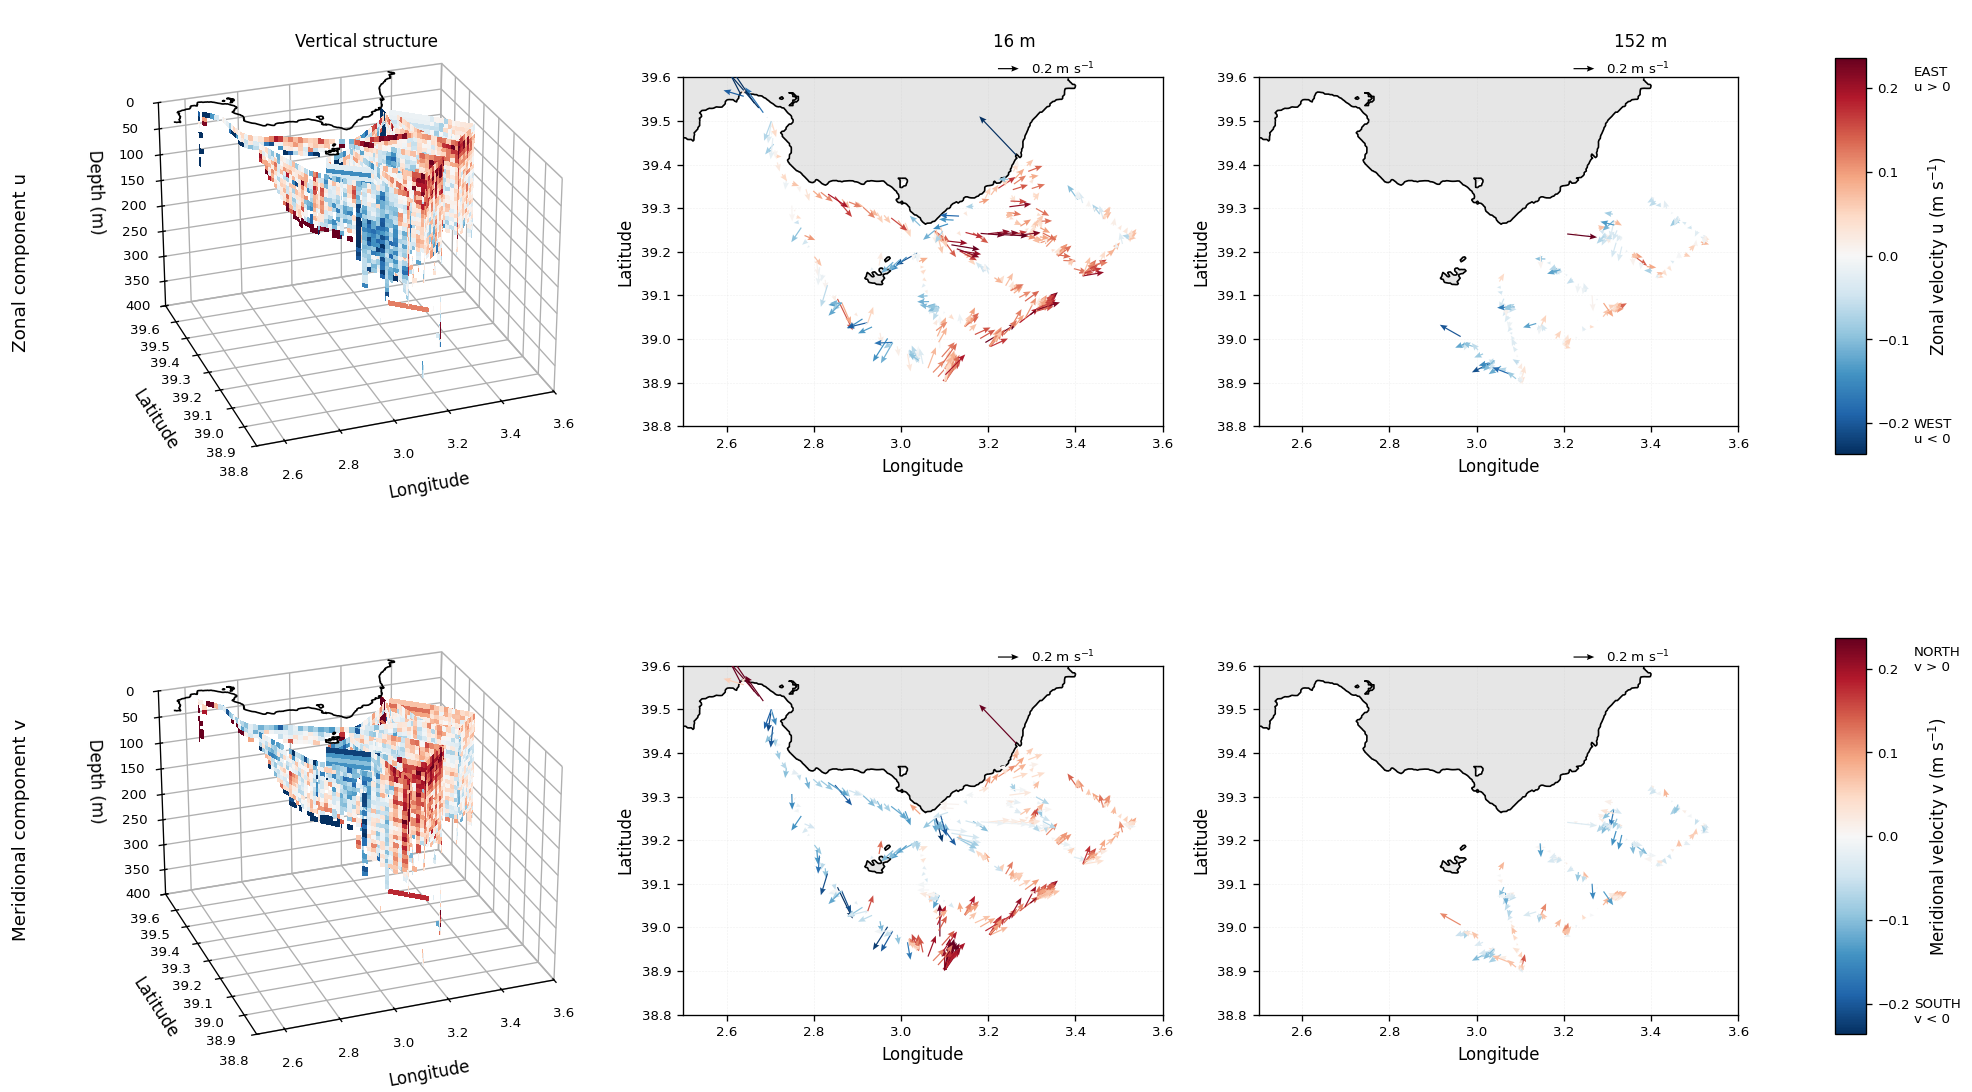

In [51]:
# ============================================================
# ADCP COMBINED FIGURE
#
# ROW 1:
#   Zonal component u
#   - 3D curtain
#   - near-surface vector map
#   - ~150 m vector map
#
# ROW 2:
#   Meridional component v
#   - 3D curtain
#   - near-surface vector map
#   - ~150 m vector map
#
# COLOUR:
#
# u:
#   blue = westward  (u < 0)
#   red  = eastward  (u > 0)
#
# v:
#   blue = southward (v < 0)
#   red  = northward (v > 0)
#
# Arrow direction + length = full current vector (u, v)
#
# No ship trajectory
# GEBCO coastline only
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl

from pathlib import Path


# ============================================================
# USER PATHS
# ============================================================

ADCP_FILE = r"C:\Users\Lara\SOCIB_LPF\Data_cruises\dep0085_socib-rv_scb-rdi001_L1_2026-07-13_data_dt.nc"

BATHY_FILE = r"C:\Users\Lara\SOCIB_LPF\Phyton_codes\figuras_cabrera_expert\GEBCO_27_Mar_2026\gebco_2025_n40.5_s38.0_w0.0_e5.0.nc"


# ============================================================
# OUTPUT
# ============================================================

OUTDIR = Path(
    r"C:\Users\Lara\SOCIB_LPF\Data_cruises\figuras_adcp_combined"
)

OUTDIR.mkdir(
    parents=True,
    exist_ok=True
)

SAVE_FIGS = True

print("Output directory:")
print(OUTDIR)
print(OUTDIR.resolve())


# ============================================================
# SETTINGS
# ============================================================

GOOD_QC = [1, 2]

MAX_ADCP_DEPTH = 400


# ------------------------------------------------------------
# 3D CURTAIN DECIMATION
# ------------------------------------------------------------

TRACK_SKIP_3D = 2
DEPTH_SKIP = 1


# ------------------------------------------------------------
# ARROW MAP SETTINGS
# ------------------------------------------------------------

# Smaller = more arrows
QUIVER_SKIP = 2

# Lower = longer arrows
QUIVER_SCALE = 4.2

REFERENCE_SPEED = 0.2


# ------------------------------------------------------------
# TARGET DEPTH
# ------------------------------------------------------------

DEEP_TARGET_DEPTH = 150


# ------------------------------------------------------------
# MAP DOMAIN
# ------------------------------------------------------------

xmin, xmax = 2.5, 3.6
ymin, ymax = 38.8, 39.6


# ------------------------------------------------------------
# 3D VIEW
# ------------------------------------------------------------

VIEW_ELEV = 26
VIEW_AZIM = -110


# ============================================================
# MATPLOTLIB STYLE
# ============================================================

plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.facecolor": "white"
})


# ============================================================
# LOAD ADCP
# ============================================================

ds = xr.open_dataset(
    ADCP_FILE
)


time = pd.to_datetime(
    ds["time"].values
)


lon = ds[
    "LON"
].values.astype(float)


lat = ds[
    "LAT"
].values.astype(float)


depth = ds[
    "DEPTH_ADCP4"
].values.astype(float)


# u = east-west component
u = ds[
    "VEL_EAS"
].values.astype(float).copy()


# v = north-south component
v = ds[
    "VEL_NOR"
].values.astype(float).copy()


qc_u = ds[
    "QC_VEL_EAS"
].values


qc_v = ds[
    "QC_VEL_NOR"
].values


qc_lon = ds[
    "QC_LON"
].values


qc_lat = ds[
    "QC_LAT"
].values


# ============================================================
# QUALITY CONTROL
# ============================================================

u[
    ~np.isin(
        qc_u,
        GOOD_QC
    )
] = np.nan


v[
    ~np.isin(
        qc_v,
        GOOD_QC
    )
] = np.nan


valid_position = (
    np.isin(
        qc_lon,
        GOOD_QC
    )
    &
    np.isin(
        qc_lat,
        GOOD_QC
    )
    &
    np.isfinite(lon)
    &
    np.isfinite(lat)
)


lon[
    ~valid_position
] = np.nan


lat[
    ~valid_position
] = np.nan


# ============================================================
# 3D DATA
# ============================================================

depth_mask = (
    depth <= MAX_ADCP_DEPTH
)


depth_plot = depth[
    depth_mask
][
    ::DEPTH_SKIP
]


u_3d = u[
    :,
    depth_mask
][
    ::TRACK_SKIP_3D,
    ::DEPTH_SKIP
]


v_3d = v[
    :,
    depth_mask
][
    ::TRACK_SKIP_3D,
    ::DEPTH_SKIP
]


lon_3d = lon[
    ::TRACK_SKIP_3D
]


lat_3d = lat[
    ::TRACK_SKIP_3D
]


# ============================================================
# REMOVE INVALID 3D POSITIONS
# ============================================================

valid_3d = (
    np.isfinite(lon_3d)
    &
    np.isfinite(lat_3d)
)


lon_3d = lon_3d[
    valid_3d
]


lat_3d = lat_3d[
    valid_3d
]


u_3d = u_3d[
    valid_3d,
    :
]


v_3d = v_3d[
    valid_3d,
    :
]


# ============================================================
# LOAD GEBCO
# ============================================================

bathy = xr.open_dataset(
    BATHY_FILE
)


lon_name = [
    c for c in bathy.coords
    if c.lower() in [
        "lon",
        "longitude",
        "x"
    ]
][0]


lat_name = [
    c for c in bathy.coords
    if c.lower() in [
        "lat",
        "latitude",
        "y"
    ]
][0]


if "elevation" in bathy:

    z_name = "elevation"

elif "z" in bathy:

    z_name = "z"

else:

    raise ValueError(
        "No bathymetry variable found."
    )


# ============================================================
# GEBCO SUBSET
# ============================================================

lat_values = bathy[
    lat_name
].values


if lat_values[0] < lat_values[-1]:

    bathy_sub = bathy.sel({
        lon_name: slice(
            xmin,
            xmax
        ),
        lat_name: slice(
            ymin,
            ymax
        )
    })

else:

    bathy_sub = bathy.sel({
        lon_name: slice(
            xmin,
            xmax
        ),
        lat_name: slice(
            ymax,
            ymin
        )
    })


blon = bathy_sub[
    lon_name
].values


blat = bathy_sub[
    lat_name
].values


bz = bathy_sub[
    z_name
].values


BLON, BLAT = np.meshgrid(
    blon,
    blat
)


# ============================================================
# COMMON COLOUR SCALE
# ============================================================

all_components = np.concatenate([
    u.ravel(),
    v.ravel()
])


all_components = all_components[
    np.isfinite(
        all_components
    )
]


VMAX = np.nanpercentile(
    np.abs(all_components),
    98
)


norm = mpl.colors.TwoSlopeNorm(
    vmin=-VMAX,
    vcenter=0,
    vmax=VMAX
)


cmap = plt.colormaps[
    "RdBu_r"
]


# ============================================================
# DEPTH INDICES FOR ARROW MAPS
# ============================================================

surface_idx = np.nanargmin(
    depth
)


deep_idx = np.argmin(
    np.abs(
        depth
        -
        DEEP_TARGET_DEPTH
    )
)


surface_depth = depth[
    surface_idx
]


deep_depth = depth[
    deep_idx
]


print(
    "Near-surface ADCP bin:",
    surface_depth,
    "m"
)

print(
    "150 m target -> actual bin:",
    deep_depth,
    "m"
)


# ============================================================
# 2D COASTLINE MAP
# ============================================================

def draw_coastline_map(
    ax
):

    # --------------------------------------------------------
    # LAND
    # --------------------------------------------------------

    land = np.ma.masked_where(
        bz < 0,
        bz
    )


    ax.contourf(
        blon,
        blat,
        land,
        levels=[
            0,
            10000
        ],
        colors=[
            "0.90"
        ],
        zorder=0
    )


    # --------------------------------------------------------
    # COASTLINE
    # --------------------------------------------------------

    ax.contour(
        blon,
        blat,
        bz,
        levels=[0],
        colors="black",
        linewidths=1.0,
        zorder=1
    )


    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    ax.set_xlim(
        xmin,
        xmax
    )

    ax.set_ylim(
        ymin,
        ymax
    )


    ax.set_xlabel(
        "Longitude"
    )

    ax.set_ylabel(
        "Latitude"
    )


    ax.set_aspect(
        "equal",
        adjustable="box"
    )


    ax.grid(
        True,
        linestyle="--",
        linewidth=0.35,
        alpha=0.18
    )


# ============================================================
# DRAW 3D CURTAIN
# ============================================================

def draw_3d_curtain(
    ax,
    component
):

    # --------------------------------------------------------
    # COASTLINE ONLY
    # --------------------------------------------------------

    ax.contour(
        BLON,
        BLAT,
        bz,
        levels=[0],
        colors="black",
        linewidths=1.0,
        zdir="z",
        offset=0
    )


    # --------------------------------------------------------
    # ADCP CURTAINS
    # --------------------------------------------------------

    for i in range(
        len(lon_3d) - 1
    ):

        c0 = component[
            i,
            :
        ]

        c1 = component[
            i + 1,
            :
        ]


        if (
            np.all(
                ~np.isfinite(c0)
            )
            and
            np.all(
                ~np.isfinite(c1)
            )
        ):

            continue


        X = np.vstack([
            np.full(
                len(depth_plot),
                lon_3d[i]
            ),
            np.full(
                len(depth_plot),
                lon_3d[i + 1]
            )
        ])


        Y = np.vstack([
            np.full(
                len(depth_plot),
                lat_3d[i]
            ),
            np.full(
                len(depth_plot),
                lat_3d[i + 1]
            )
        ])


        Z = np.vstack([
            depth_plot,
            depth_plot
        ])


        C = np.vstack([
            c0,
            c1
        ])


        C_colour = np.where(
            np.isfinite(C),
            C,
            0
        )


        facecolors = cmap(
            norm(
                C_colour
            )
        )


        facecolors[
            ~np.isfinite(C),
            3
        ] = 0


        ax.plot_surface(
            X,
            Y,
            Z,
            facecolors=facecolors,
            shade=False,
            linewidth=0,
            antialiased=False,
            rstride=1,
            cstride=1
        )


    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    ax.set_xlim(
        xmin,
        xmax
    )

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_zlim(
        MAX_ADCP_DEPTH,
        0
    )


    ax.set_xlabel(
        "Longitude",
        labelpad=7
    )

    ax.set_ylabel(
        "Latitude",
        labelpad=7
    )

    ax.set_zlabel(
        "Depth (m)",
        labelpad=6
    )


    # --------------------------------------------------------
    # VIEW
    # --------------------------------------------------------

    ax.view_init(
        elev=VIEW_ELEV,
        azim=VIEW_AZIM
    )


    # --------------------------------------------------------
    # CLEAN PANES
    # --------------------------------------------------------

    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False


    ax.xaxis.pane.set_edgecolor(
        "0.85"
    )

    ax.yaxis.pane.set_edgecolor(
        "0.85"
    )

    ax.zaxis.pane.set_edgecolor(
        "0.85"
    )


# ============================================================
# DRAW ARROW MAP
# ============================================================

def draw_arrow_map(
    ax,
    depth_index,
    colour_component
):

    # --------------------------------------------------------
    # FULL VECTOR
    # --------------------------------------------------------

    uu = u[
        :,
        depth_index
    ]


    vv = v[
        :,
        depth_index
    ]


    # --------------------------------------------------------
    # COLOUR VARIABLE
    # --------------------------------------------------------

    if colour_component == "u":

        cc = uu

    elif colour_component == "v":

        cc = vv

    else:

        raise ValueError(
            "colour_component must be 'u' or 'v'"
        )


    # --------------------------------------------------------
    # VALID DATA
    # --------------------------------------------------------

    valid = (
        np.isfinite(lon)
        &
        np.isfinite(lat)
        &
        np.isfinite(uu)
        &
        np.isfinite(vv)
        &
        np.isfinite(cc)
    )


    lon_q = lon[
        valid
    ][
        ::QUIVER_SKIP
    ]


    lat_q = lat[
        valid
    ][
        ::QUIVER_SKIP
    ]


    u_q = uu[
        valid
    ][
        ::QUIVER_SKIP
    ]


    v_q = vv[
        valid
    ][
        ::QUIVER_SKIP
    ]


    c_q = cc[
        valid
    ][
        ::QUIVER_SKIP
    ]


    # --------------------------------------------------------
    # BASE MAP
    # --------------------------------------------------------

    draw_coastline_map(
        ax
    )


    # --------------------------------------------------------
    # ARROWS
    # --------------------------------------------------------

    q = ax.quiver(
        lon_q,
        lat_q,

        u_q,
        v_q,

        c_q,

        cmap=cmap,
        norm=norm,

        angles="xy",

        scale_units="xy",

        scale=QUIVER_SCALE,

        width=0.0025,

        headwidth=5.0,
        headlength=6.2,
        headaxislength=5.4,

        pivot="tail",

        minlength=0.4,

        zorder=5
    )


    # --------------------------------------------------------
    # REFERENCE VECTOR
    # --------------------------------------------------------

    ax.quiverkey(
        q,

        X=0.70,
        Y=1.025,

        U=REFERENCE_SPEED,

        label=(
            f"{REFERENCE_SPEED:.1f} "
            "m s$^{-1}$"
        ),

        labelpos="E",

        coordinates="axes",

        fontproperties={
            "size": 8
        }
    )


    return q


# ============================================================
# CREATE FIGURE
# ============================================================

fig = plt.figure(
    figsize=(18, 11)
)


# ============================================================
# ROW 1 — u
# ============================================================

ax_u_3d = fig.add_subplot(
    2,
    3,
    1,
    projection="3d"
)


draw_3d_curtain(
    ax=ax_u_3d,
    component=u_3d
)


ax_u_surface = fig.add_subplot(
    2,
    3,
    2
)


draw_arrow_map(
    ax=ax_u_surface,
    depth_index=surface_idx,
    colour_component="u"
)


ax_u_150 = fig.add_subplot(
    2,
    3,
    3
)


draw_arrow_map(
    ax=ax_u_150,
    depth_index=deep_idx,
    colour_component="u"
)


# ============================================================
# ROW 2 — v
# ============================================================

ax_v_3d = fig.add_subplot(
    2,
    3,
    4,
    projection="3d"
)


draw_3d_curtain(
    ax=ax_v_3d,
    component=v_3d
)


ax_v_surface = fig.add_subplot(
    2,
    3,
    5
)


draw_arrow_map(
    ax=ax_v_surface,
    depth_index=surface_idx,
    colour_component="v"
)


ax_v_150 = fig.add_subplot(
    2,
    3,
    6
)


draw_arrow_map(
    ax=ax_v_150,
    depth_index=deep_idx,
    colour_component="v"
)


# ============================================================
# LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.065,
    right=0.82,
    top=0.90,
    bottom=0.07,
    wspace=0.20,
    hspace=0.16
)


# ============================================================
# COLUMN LABELS
# ============================================================

fig.text(
    0.185,
    0.880,
    "Vertical structure",
    ha="center",
    va="bottom",
    fontsize=10
)


fig.text(
    0.485,
    00.880,
    f"{surface_depth:.0f} m",
    ha="center",
    va="bottom",
    fontsize=10
)


fig.text(
    0.775,
    0.880,
    f"{deep_depth:.0f} m",
    ha="center",
    va="bottom",
    fontsize=10
)


# ============================================================
# ROW LABELS
# ============================================================

fig.text(
    0.025,
    0.70,
    "Zonal component u",
    rotation=90,
    va="center",
    ha="center",
    fontsize=11
)


fig.text(
    0.025,
    0.27,
    "Meridional component v",
    rotation=90,
    va="center",
    ha="center",
    fontsize=11
)


# ============================================================
# COLORBAR AXES
# ============================================================

cax_u = fig.add_axes([
    0.865,
    0.555,
    0.014,
    0.30
])


cax_v = fig.add_axes([
    0.865,
    0.115,
    0.014,
    0.30
])


# ============================================================
# COLORBAR u
# ============================================================

sm_u = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm_u.set_array([])


cbar_u = fig.colorbar(
    sm_u,
    cax=cax_u
)


cbar_u.set_label(
    "Zonal velocity u (m s$^{-1}$)",
    labelpad=10
)


cax_u.text(
    2.6,
    0.98,
    "EAST\nu > 0",
    transform=cax_u.transAxes,
    ha="left",
    va="top",
    fontsize=8
)


cax_u.text(
    2.6,
    0.02,
    "WEST\nu < 0",
    transform=cax_u.transAxes,
    ha="left",
    va="bottom",
    fontsize=8
)


# ============================================================
# COLORBAR v
# ============================================================

sm_v = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm_v.set_array([])


cbar_v = fig.colorbar(
    sm_v,
    cax=cax_v
)


cbar_v.set_label(
    "Meridional velocity v (m s$^{-1}$)",
    labelpad=10
)


cax_v.text(
    2.6,
    0.98,
    "NORTH\nv > 0",
    transform=cax_v.transAxes,
    ha="left",
    va="top",
    fontsize=8
)


cax_v.text(
    2.6,
    0.02,
    "SOUTH\nv < 0",
    transform=cax_v.transAxes,
    ha="left",
    va="bottom",
    fontsize=8
)


# ============================================================
# SAVE
# ============================================================

outfile = OUTDIR / "ADCP_uv_3D_and_vector_maps.png"

print("Saving figure to:")
print(outfile)


if SAVE_FIGS:

    fig.savefig(
        str(outfile),
        dpi=300,
        bbox_inches="tight"
    )


plt.show()